# *Flaviviridae* glycoprotein fold trees: robustness of ultrametricity

`flaviviridae_trees.ipynb` finds that ESM3Di trees are closer to ultrametric than AlphaFold2 trees: their
root-to-tip distances vary less. Is that difference robust, and what could explain it?

**Measure.** Ultrametricity: the variance of the root-to-tip distances of the MAD-rooted tree after dividing them by
their mean (Moi et al. 2025, eq. 2). 0 means all tips are equally far from the root. Lower is not by itself more
accurate; it means more even distances.

**Tests**, each comparing ESM3Di with AlphaFold2 on the same sequences, without unclassified tips:

1. **Sequence choice:** paired jackknife deleting 20% and 50% of the sequences (`flaviviridae_jackknife.ipynb`).
2. **Root:** the lowest CV over all root positions, which does not depend on MAD rooting.
3. **Clades:** leaving out one group at a time, because sequences of a group are not independent.
4. **Outlier tips:** the interquartile range / median of the depths, which long tips hardly affect.
5. **Distance:** the same trees with other transforms of fident, because the workflow's transform rises steeply
   at low identity (fident 0.1 gives 3.2, 0.05 gives 8.6).
6. **Structure quality and 3Di alphabet:** whether long AlphaFold2 tips are low-confidence structures (and E
   without ESMFold structures), and whether depth follows the entropy of the 3Di.

**Not tested:** an amino-acid baseline. The IQ-TREE runs in `aa_per_protein` were stopped before convergence.

Run `flaviviridae_trees.ipynb` first. Results are cached in `results/`; remove them to recompute, preferably on a
compute node. The figure, `figures/flaviviridae_jackknife`, shows the delete-20% replicates of
the monophyly score and of the CV; the other tests are the tables below.


In [1]:
import os
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from foldtree_resample import build_tree, jackknife, jukes_cantor_taylor, load_allvall
from monophyly import glycoprotein_labels, relabel_tree, root_to_tip_depths, score_monophyly, ultrametricity, ultrametricity_best_root

sys.path.insert(0, "../../../benchmarks")   # shared style of the paper figures
from pub_style import METHOD_COLOURS, MM, WIDTH_ONEHALF, save_pub, use_pub_style

use_pub_style()

INPUT_DIR = Path("flaviviridae_inputs")
OUTPUT_DIR = Path("/scratch/fweikert/phylogeny/flaviviridae")    # esm3di foldtree runs of flaviviridae_trees.ipynb
PDB_DIR = Path("/scratch/fweikert/glyco_pdbs")                   # structures with pLDDT in the B-factor column
JACKKNIFE_CSV = Path("results/flaviviridae_ultrametricity_jackknife.csv")
SENSITIVITY_CSV = Path("results/flaviviridae_ultrametricity_sensitivity.csv")
FIGURE_DIR = Path("figures")

REPLICATES = 100
FRACTIONS = (0.8, 0.5)   # share of sequences kept per replicate
SEED = 1
WORKERS = min(6, os.cpu_count())
MIN_PLDDT = 70           # "confident" in AlphaFold2

DATASETS = {"fullglyco_E": "E", "fullglyco_E1": "E1", "fullglyco_E2": "E2"}
MODELS = {"esm3di": "ESM3Di", "af2": "AlphaFold2"}
COLOURS = {"ESM3Di": METHOD_COLOURS["ESM3Di"], "AlphaFold2": METHOD_COLOURS["Foldseek"]}

QUICKTREE = next(OUTPUT_DIR.glob(".snakemake_conda/*/bin/quicktree"))
labels = glycoprotein_labels({p: INPUT_DIR / f"refolded_fullglyco_{p}_aa.fas" for p in DATASETS.values()})
allvall = {dataset: {model: load_allvall(OUTPUT_DIR / f"{model}_{dataset}" / "allvall_1.csv") for model in MODELS}
           for dataset in DATASETS}


def classified(table):
    """The all-vs-all table without the tips with an unclassified code."""
    unclassified = {name for name in set(table["query"]) if labels[name][4:6] == "UN"}
    return table[~table["query"].isin(unclassified) & ~table["target"].isin(unclassified)]


allvall = {dataset: {model: classified(table) for model, table in tables.items()} for dataset, tables in allvall.items()}
tips = {dataset: sorted(set(tables["esm3di"]["query"])) for dataset, tables in allvall.items()}


def tree_measures(table, keep=None, transform=jukes_cantor_taylor):
    """Monophyly score, CV at the MAD root and at the best root, IQR / median and depths of the tree of ``keep``."""
    if keep is not None:
        table = table[table["query"].isin(keep) & table["target"].isin(keep)]
    with tempfile.TemporaryDirectory() as workdir:
        tree = build_tree(table, workdir, QUICKTREE, transform)
        depths = root_to_tip_depths(tree)
        values = np.array(list(depths.values()))
        monophyly = score_monophyly(relabel_tree(tree, Path(workdir) / "labelled.nwk", labels), verbose=False)[2]
        return dict(tips=len(values), monophyly=monophyly, cv=ultrametricity(tree), best_root_cv=ultrametricity_best_root(tree),
                    iqr_median=float(np.subtract(*np.percentile(values, [75, 25])) / np.median(values)),
                    mean_depth=float(values.mean())), depths


## 1. The trees of all classified sequences

Rebuilt without the unclassified tips, so these can differ slightly from the pruned trees of
`flaviviridae_trees.ipynb`. `pairs_fident_0`: pairs without any identity, whose distance is capped far above all
others by the transform, as a check that a few such pairs do not stretch the trees.


In [2]:
rows, depths = [], {}
for dataset, protein in DATASETS.items():
    for model, method in MODELS.items():
        measures, depths[protein, method] = tree_measures(allvall[dataset][model])
        table = allvall[dataset][model]
        off = table[table["query"] != table["target"]]
        rows.append({"protein": protein, "method": method, **measures, "mean_fident": off["fident"].mean(),
                     "pairs_fident_0": int((off["fident"] == 0).sum())})
full = pd.DataFrame(rows)
print("Pearson correlation of tip depths between the methods:",
      {p: round(pd.DataFrame({m: depths[p, m] for m in MODELS.values()}).corr().iloc[0, 1], 3) for p in DATASETS.values()})
full.round(3)


Pearson correlation of tip depths between the methods: {'E': np.float64(0.62), 'E1': np.float64(-0.198), 'E2': np.float64(0.798)}


,protein,method,tips,monophyly,cv,best_root_cv,iqr_median,mean_depth,mean_fident,pairs_fident_0
0,E,ESM3Di,236,0.898,0.014,0.009,0.129,1.537,0.188,2
1,E,AlphaFold2,236,0.915,0.021,0.012,0.139,1.452,0.203,1
2,E1,ESM3Di,189,0.957,0.008,0.008,0.125,1.225,0.221,0
3,E1,AlphaFold2,189,0.963,0.013,0.013,0.204,1.392,0.232,0
4,E2,ESM3Di,188,0.979,0.013,0.011,0.150,1.339,0.175,0
5,E2,AlphaFold2,188,0.968,0.027,0.021,0.281,1.450,0.184,5


## 2. Sequence choice and root: paired jackknife

Each replicate keeps the same random sequences for both methods and rebuilds both trees. The monophyly scores of
the 20% replicates must equal `results/flaviviridae_jackknife.csv`, which checks this run against the earlier one.

`se` is the delete-d jackknife standard error of the difference, `sqrt((n - k) / (k * R) * sum((d_r - mean d)^2))`
for `k` deleted of `n` sequences and `R` replicates. It treats sequences as independent, which related viruses are
not, so test 3 complements it. The shares and percentile ranges are descriptive.


In [3]:
if JACKKNIFE_CSV.exists():
    replicates = pd.read_csv(JACKKNIFE_CSV)
    print(f"Loaded {len(replicates)} rows from {JACKKNIFE_CSV}")
else:
    tables = []
    for dataset, protein in DATASETS.items():
        for fraction in FRACTIONS:
            print(f"{protein}, keep {fraction}: {REPLICATES} replicates on {WORKERS} workers", flush=True)
            table = jackknife({MODELS[m]: allvall[dataset][m] for m in MODELS}, labels, QUICKTREE,
                              replicates=REPLICATES, fraction=fraction, seed=SEED, workers=WORKERS)
            tables.append(table.assign(dataset=protein, fraction_kept=fraction))
    replicates = pd.concat(tables, ignore_index=True)
    replicates.to_csv(JACKKNIFE_CSV, index=False)

earlier = pd.read_csv("results/flaviviridae_jackknife.csv").set_index(["dataset", "replicate", "method"])["fraction"]
same = replicates[replicates["fraction_kept"] == 0.8].set_index(["dataset", "replicate", "method"])["fraction"]
assert np.allclose(same.loc[earlier.index], earlier), "replicates differ from flaviviridae_jackknife.csv"

summary = []
for (protein, fraction), group in replicates.groupby(["dataset", "fraction_kept"], sort=False):
    n = len(tips[next(d for d, p in DATASETS.items() if p == protein)])
    deleted = n - group["tips"].iloc[0]
    for measure in ("fraction", "root_to_tip_cv", "best_root_cv"):
        paired = group.pivot(index="replicate", columns="method", values=measure)
        d = paired["ESM3Di"] - paired["AlphaFold2"]
        se = np.sqrt((n - deleted) / (deleted * len(d)) * ((d - d.mean()) ** 2).sum())
        summary.append({"protein": protein, "kept": fraction, "measure": measure, "ESM3Di": paired["ESM3Di"].mean(),
                        "AlphaFold2": paired["AlphaFold2"].mean(), "difference": d.mean(), "se": se,
                        "2.5%": d.quantile(0.025), "97.5%": d.quantile(0.975), "ESM3Di lower": (d < 0).mean(), "equal": (d == 0).mean(), "ESM3Di higher": (d > 0).mean()})
jackknife_summary = pd.DataFrame(summary)
jackknife_summary.to_csv("results/flaviviridae_ultrametricity_summary.csv", index=False)
jackknife_summary.round(3)


E, keep 0.8: 100 replicates on 6 workers


E, keep 0.5: 100 replicates on 6 workers


E1, keep 0.8: 100 replicates on 6 workers


E1, keep 0.5: 100 replicates on 6 workers


E2, keep 0.8: 100 replicates on 6 workers


E2, keep 0.5: 100 replicates on 6 workers


,protein,kept,measure,ESM3Di,AlphaFold2,difference,se,2.5%,97.5%,ESM3Di lower,equal,ESM3Di higher
0,E,0.8,fraction,0.895,0.902,-0.007,0.030,-0.032,0.021,0.59,0.12,0.29
1,E,0.8,root_to_tip_cv,0.012,0.036,-0.024,0.040,-0.064,0.000,0.97,0.00,0.03
2,E,0.8,best_root_cv,0.009,0.014,-0.005,0.009,-0.014,0.001,0.94,0.00,0.06
3,E,0.5,fraction,0.874,0.874,0.000,0.021,-0.034,0.043,0.50,0.11,0.39
4,E,0.5,root_to_tip_cv,0.011,0.030,-0.019,0.017,-0.060,-0.000,0.98,0.00,0.02
5,E,0.5,best_root_cv,0.009,0.017,-0.008,0.006,-0.018,0.001,0.94,0.00,0.06
6,E1,0.8,fraction,0.960,0.966,-0.007,0.039,-0.047,0.023,0.52,0.11,0.37
7,E1,0.8,root_to_tip_cv,0.009,0.010,-0.001,0.009,-0.009,0.008,0.56,0.00,0.44
8,E1,0.8,best_root_cv,0.009,0.010,-0.001,0.009,-0.009,0.007,0.58,0.00,0.42
9,E1,0.5,fraction,0.950,0.951,-0.001,0.028,-0.049,0.054,0.44,0.13,0.43


## 3–6. Clades, distance and structure quality

Every row rebuilds both trees of a protein on the same sequences.


In [4]:
def plddt(path):
    values = [float(line[60:66]) for line in open(path) if line.startswith("ATOM") and line[12:16].strip() == "CA"]
    return float(np.mean(values))


def group_of(tip):
    return labels[tip][2:6]


confidence = {dataset: {pdb.stem: plddt(pdb) for pdb in (PDB_DIR / f"refolded_{dataset}").glob("*.pdb")} for dataset in DATASETS}
TRANSFORMS = {"distance 1 - fident": lambda k: k, "distance -ln(fident)": lambda k: -np.log(np.clip(1 - k, 0.01, None))}

if SENSITIVITY_CSV.exists():
    sensitivity = pd.read_csv(SENSITIVITY_CSV)
    print(f"Loaded {len(sensitivity)} rows from {SENSITIVITY_CSV}")
else:
    rows = []

    def add(protein, test, dataset, keep=None, transform=jukes_cantor_taylor):
        values = {method: tree_measures(allvall[dataset][model], keep, transform)[0] for model, method in MODELS.items()}
        rows.append({"protein": protein, "test": test, "tips": values["ESM3Di"]["tips"],
                     **{f"{method} {name}": value for method, measures in values.items() for name, value in measures.items() if name != "tips"}})

    for dataset, protein in DATASETS.items():
        add(protein, "all classified sequences", dataset)
        for group in sorted({group_of(tip) for tip in tips[dataset]}):
            add(protein, f"without {group}", dataset, [tip for tip in tips[dataset] if group_of(tip) != group])
        for name, transform in TRANSFORMS.items():
            add(protein, name, dataset, transform=transform)
        confident = [tip for tip in tips[dataset] if confidence[dataset][tip] >= MIN_PLDDT]
        add(protein, f"structures with pLDDT >= {MIN_PLDDT}", dataset, confident)
        if protein == "E":
            add(protein, "without ESMFold structures", dataset, [tip for tip in tips[dataset] if "ESMFold" not in tip])
    sensitivity = pd.DataFrame(rows)
    sensitivity.to_csv(SENSITIVITY_CSV, index=False)

sensitivity["difference"] = sensitivity["ESM3Di cv"] - sensitivity["AlphaFold2 cv"]
sensitivity["best_root_difference"] = sensitivity["ESM3Di best_root_cv"] - sensitivity["AlphaFold2 best_root_cv"]
sensitivity["iqr_median_difference"] = sensitivity["ESM3Di iqr_median"] - sensitivity["AlphaFold2 iqr_median"]
sensitivity[["protein", "test", "tips", "ESM3Di cv", "AlphaFold2 cv", "difference", "best_root_difference", "iqr_median_difference"]].round(3)


,protein,test,tips,ESM3Di cv,AlphaFold2 cv,difference,best_root_difference,iqr_median_difference
0,E,all classified sequences,236,0.014,0.021,-0.007,-0.003,-0.010
1,E,without FJAF,229,0.015,0.024,-0.009,-0.004,-0.016
2,E,without FJFL,226,0.010,0.065,-0.055,-0.010,-0.076
3,E,without FJIS,201,0.009,0.067,-0.058,-0.010,-0.044
4,E,without FJJI,217,0.016,0.015,0.001,0.000,0.020
5,E,without FJMB,167,0.023,0.041,-0.018,-0.002,-0.037
6,E,without FJNV,227,0.016,0.060,-0.043,-0.009,-0.061
7,E,without FJTB,220,0.014,0.064,-0.050,-0.009,-0.086
8,E,without PLLG,165,0.013,0.017,-0.004,-0.004,0.015
9,E,distance 1 - fident,236,0.000,0.000,0.000,0.000,-0.001


### What depth follows

Spearman correlation over tips: of the depth in each tree with the confidence of the structure and with the 3Di
entropy of the tip in that tree, and of the depth difference with the entropy difference. Correlations only: a
low value argues against a simple explanation, a high one does not prove it.


In [5]:
def read_3di(model, dataset):
    """3Di string per tip of a run's Foldseek database."""
    run = OUTPUT_DIR / f"{model}_{dataset}"
    names = dict(line.split("\t")[:2] for line in open(run / "db.lookup"))
    data = (run / "db_ss").read_bytes()
    sequences = {}
    for line in open(run / "db_ss.index"):
        key, offset, length = line.split()[:3]
        sequences[names[key].removesuffix(".pdb")] = data[int(offset):int(offset) + int(length)].rstrip(b"\x00\n").decode()
    return sequences


def entropy(sequence):
    shares = np.unique(list(sequence), return_counts=True)[1] / len(sequence)
    return float(-(shares * np.log2(shares)).sum())


rows = []
for dataset, protein in DATASETS.items():
    table = pd.DataFrame({"plddt": pd.Series(confidence[dataset])})
    for model, method in MODELS.items():
        states = read_3di(model, dataset)
        table[f"{method} depth"] = pd.Series(depths[protein, method])
        table[f"{method} entropy"] = pd.Series({tip: entropy(states[tip]) for tip in states})
    table = table.dropna()
    rows.append({"protein": protein, "tips": len(table),
                 **{f"{m} depth ~ pLDDT": table[f"{m} depth"].corr(table["plddt"], method="spearman") for m in MODELS.values()},
                 **{f"{m} depth ~ entropy": table[f"{m} depth"].corr(table[f"{m} entropy"], method="spearman") for m in MODELS.values()},
                 "depth difference ~ entropy difference": (table["AlphaFold2 depth"] - table["ESM3Di depth"]).corr(
                     table["AlphaFold2 entropy"] - table["ESM3Di entropy"], method="spearman"),
                 "tips below pLDDT 70": int((table["plddt"] < MIN_PLDDT).sum())})
correlations = pd.DataFrame(rows)
correlations.round(3)


,protein,tips,ESM3Di depth ~ pLDDT,AlphaFold2 depth ~ pLDDT,ESM3Di depth ~ entropy,AlphaFold2 depth ~ entropy,depth difference ~ entropy difference,tips below pLDDT 70
0,E,236,-0.079,-0.010,-0.262,-0.298,0.092,66
1,E1,189,0.116,-0.218,0.191,0.173,0.296,10
2,E2,188,-0.293,-0.404,0.357,-0.185,-0.260,40


## Conclusion

The direction favours ESM3Di for E and E2, but the size of the difference is not robust.

- **E and E2:** ESM3Di is the more ultrametric in 97% and 94% of the delete-20% replicates, also at the best root (94% and
  98%) and with `-ln(fident)` distances, and after removing low-confidence or ESMFold structures. The differences
  stay below two delete-d standard errors (0.7-1.5), and they shrink or vanish without single groups (E without FJJI,
  E2 without PLPV).
- **E1:** no difference (ESM3Di lower in 56% of the replicates, 29% when deleting 50%). The difference of the full
  tree is gone without the 10 structures below pLDDT 70.
- **Distance:** with `1 - fident` the difference disappears for all three proteins, which suggests it arises from how
  the transform stretches the distances of divergent pairs (it also compresses all values to 0.0002-0.0008).
- **E, AlphaFold2:** replicates fall into two clusters, so this value is unstable.
- **3Di alphabet:** the depth differences do not follow the entropy differences consistently.

A lower value means more even root-to-tip distances, not a more accurate tree, and there is no amino-acid baseline here.


## Figure (not in the paper; its numbers are Supplementary Table 2)

Delete-20% replicates of the trees without the unclassified sequences: monophyly score (**a**) and ultrametricity (**b**) of each replicate (points), their median (bar) and the tree of all classified sequences (diamond).


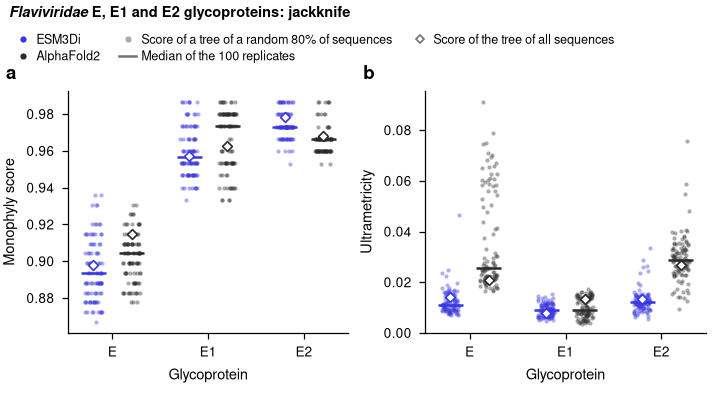

In [6]:
from matplotlib.lines import Line2D

from tree_plot import TITLE_BASELINE_MM, mm_canvas, rich_text

kept = replicates[replicates["fraction_kept"] == 0.8]
full_trees = full.set_index(["protein", "method"])

# Layout in mm
WIDTH, HEIGHT = WIDTH_ONEHALF / MM, 66
LEFT, GAP, RIGHT, TOP, BOTTOM = 11, 13, 1, 15, 10
panel_width = (WIDTH - LEFT - GAP - RIGHT) / 2

fig = plt.figure(figsize=(WIDTH * MM, HEIGHT * MM))
canvas = mm_canvas(fig, WIDTH, HEIGHT)
rich_text(canvas, 1, TITLE_BASELINE_MM, [("Flaviviridae", dict(fontweight="bold", fontstyle="italic")),
                                         (" E, E1 and E2 glycoproteins: jackknife", dict(fontweight="bold"))], fontsize=7, va="baseline")
rng = np.random.default_rng(0)
panels = (("a", "fraction", "monophyly", "Monophyly score"),
          ("b", "root_to_tip_cv", "cv", "Ultrametricity"))
for column, (letter, measure, reference, label) in enumerate(panels):
    x_left = LEFT + column * (panel_width + GAP)
    ax = fig.add_axes((x_left / WIDTH, BOTTOM / HEIGHT, panel_width / WIDTH, (HEIGHT - TOP - BOTTOM) / HEIGHT))
    for x, protein in enumerate(DATASETS.values()):
        for offset, method in zip((-0.2, 0.2), MODELS.values()):
            values = kept[(kept["dataset"] == protein) & (kept["method"] == method)][measure]
            ax.scatter(x + offset + rng.uniform(-0.09, 0.09, len(values)), values, s=4, alpha=0.4, linewidths=0, color=COLOURS[method])
            ax.hlines(values.median(), x + offset - 0.13, x + offset + 0.13, color=COLOURS[method], lw=1.2)
            ax.scatter(x + offset, full_trees.loc[(protein, method), reference], marker="D", s=11, color="white",
                       edgecolors=COLOURS[method], linewidths=0.8, zorder=3)
    ax.set_xticks(range(len(DATASETS)), DATASETS.values())
    ax.set_xlabel("Glycoprotein")
    ax.set_ylabel(label)
    if measure == "root_to_tip_cv":
        ax.set_ylim(bottom=0)
    canvas.text(x_left - LEFT + 0.5, TOP - 2, letter, fontsize=9, fontweight="bold", va="baseline")

# Key: the methods by colour, then what each mark is
key = "0.45"
dot = dict(marker="o", ls="none", ms=3, mew=0)
handles = [Line2D([], [], color=COLOURS[method], label=method, **dot) for method in MODELS.values()]
handles += [Line2D([], [], color=key, alpha=0.6, label="Score of a tree of a random 80% of sequences", **dot),
            Line2D([], [], color=key, lw=1.2, label="Median of the 100 replicates"),
            Line2D([], [], marker="D", ls="none", ms=3, mfc="white", mec=key, mew=0.8, label="Score of the tree of all sequences")]
fig.legend(handles=handles, frameon=False, ncol=3, loc="upper left", bbox_to_anchor=(1 / WIDTH, 1 - 4.5 / HEIGHT), borderaxespad=0,
           handlelength=1.4, handletextpad=0.4, columnspacing=1.5, labelspacing=0.25, fontsize=6)
save_pub(fig, "flaviviridae_jackknife", FIGURE_DIR)
fig.savefig(FIGURE_DIR / "flaviviridae_jackknife.svg")
plt.show()
